#  Superstore Sales Analysis — Exploratory Data Analysis (EDA)

## Notebook Purpose
This notebook performs **Exploratory Data Analysis (EDA)** on the cleaned Superstore
sales dataset. The goal is to understand the underlying structure, distributions,
and statistical behavior of the data before answering specific business questions
in Notebook 4.

## What This Notebook Covers
1. Univariate analysis of numerical variables (distributions, spread, skewness)
2. Univariate analysis of categorical variables (frequency, proportions)
3. Outlier detection and investigation (IQR-based)
4. Correlation analysis between numerical variables
5. Bivariate exploration (numeric vs categorical relationships)
6. Profitability pattern exploration
7. Time-based structure validation
8. Data quality recheck on the freshly loaded dataset

## What This Notebook Does NOT Cover
This notebook does **not** answer specific business questions (e.g. "which region
is most profitable?"). That level of interpretation belongs to Notebook 4
(`04_business_analysis.ipynb`). EDA is about understanding *what the data looks
like*; business analysis is about *what it means for the business*.

## Dataset
- **Source:** `superstore_cleaned.csv` (output of Notebook 2)
- **Shape:** 8,399 rows × 33 columns
- **Period:** January 2009 – December 2012

## Key Context Carried Forward From Cleaning
- 50.77% of orders are unprofitable — a major theme to keep exploring here
- No missing values or duplicates (verified in Notebook 2)
- `discount` is stored as a decimal (0.05 = 5%)
- `profit_margin` is already in percentage form
- Known outliers to investigate: `shipping_days` max = 92, `profit_margin` min = -1144%

---

## 1️ Setup & Data Loading

We begin by connecting to Google Drive, importing required libraries, and loading
the cleaned dataset produced in Notebook 2. Display options are configured for
clean, readable numeric output throughout this notebook.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.2f}")

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

df = pd.read_csv(
    "/content/drive/MyDrive/Superstore-Analysis/superstore_cleaned.csv"
)

print(f"Dataset loaded: {df.shape[0]:,} rows × {df.shape[1]} columns")

Mounted at /content/drive
Dataset loaded: 8,399 rows × 33 columns


## 2️ Data Quality Recheck

Although the dataset was cleaned in Notebook 2, this is a fresh Python session with
a freshly loaded CSV file. CSV files do not preserve pandas dtypes (e.g. `datetime64`)
automatically — they can silently revert to plain text on reload. This quick recheck
confirms:

- No missing values were introduced during save/reload
- No duplicate rows exist
- All columns still hold their correct data types (especially `order_date` and
  `ship_date`, which must remain datetime for time-based analysis later)

This step takes seconds but prevents confusing errors later in the notebook.

In [ ]:
print("Missing Values Per Column:")
print(df.isnull().sum().sum(), "total missing values across the dataset\n")

print("Duplicate Rows:")
print(df.duplicated().sum(), "duplicate rows found\n")

print("Data Types:")
print(df.dtypes)

Missing Values Per Column:
0 total missing values across the dataset

Duplicate Rows:
0 duplicate rows found

Data Types:
row_id                    int64
order_id                  int64
order_date               object
order_priority           object
order_quantity            int64
sales                   float64
discount                float64
ship_mode                object
profit                  float64
unit_price              float64
shipping_cost           float64
customer_name            object
city                     object
zip_code                  int64
state                    object
region                   object
customer_segment         object
product_category         object
product_sub_category     object
product_name             object
product_container        object
product_base_margin     float64
ship_date                object
shipping_days             int64
profit_margin           float64
year                      int64
month                     int64
month_name    

### Fixing Data Types

`order_date` and `ship_date` loaded as `object` (text) instead of `datetime64`, which
is expected CSV behavior — pandas datetime types are not preserved when saving to CSV.
We convert them back to datetime here so date-based operations work correctly
throughout this notebook.

In [ ]:
df['order_date'] = pd.to_datetime(df['order_date'])
df['ship_date'] = pd.to_datetime(df['ship_date'])

print(df[['order_date', 'ship_date']].dtypes)

order_date    datetime64[ns]
ship_date     datetime64[ns]
dtype: object


### Restoring Category Data Types

`discount_band` and `sales_band` were created as ordered `category` types in Notebook 2,
but like datetime, this type does not survive a CSV save/reload and reverts to plain
`object`. We restore them here as **ordered categories** so that:

- Plots and group-by operations respect the logical order (e.g. "No Discount" →
  "Low" → "Medium" → "High") instead of sorting alphabetically
- Memory usage is more efficient for these low-cardinality columns

In [ ]:
discount_order = ["No Discount", "Low", "Medium", "High"]
sales_order = ["Small", "Medium", "Large", "Very Large"]

df["discount_band"] = pd.Categorical(df["discount_band"], categories=discount_order, ordered=True)
df["sales_band"] = pd.Categorical(df["sales_band"], categories=sales_order, ordered=True)

print(df[["discount_band", "sales_band"]].dtypes)

discount_band    category
sales_band       category
dtype: object


In [ ]:
print(df[["discount_band", "sales_band"]])

     discount_band  sales_band
0              Low      Medium
1              Low       Small
2              Low  Very Large
3              Low  Very Large
4              Low      Medium
...            ...         ...
8394           Low      Medium
8395           Low       Large
8396        Medium      Medium
8397           Low  Very Large
8398           Low  Very Large

[8399 rows x 2 columns]


In [ ]:
print("Missing after conversion:")
print(df[["discount_band", "sales_band"]].isnull().sum())

Missing after conversion:
discount_band    0
sales_band       0
dtype: int64


#### Logical consistency check: ship_date should never be before order_date


In [ ]:
inconsistent_dates = (df["ship_date"] < df["order_date"]).sum()
print(f"Rows where ship_date is before order_date: {inconsistent_dates}")

Rows where ship_date is before order_date: 0


## 3️ Univariate Analysis — Numerical Variables

Before exploring relationships between variables, we examine each numerical column
individually. This tells us the "normal" range of values, how spread out they are,
and whether the distribution is symmetric or skewed — essential context before any
comparison or business interpretation later.

**Numerical columns to explore:**
`sales`, `profit`, `discount`, `profit_margin`, `shipping_cost`, `unit_price`,
`order_quantity`, `shipping_days`, `product_base_margin`

### 3.1 Summary Statistics — Numerical Columns

We start with descriptive statistics for all numerical columns, extended with
**skewness** and **kurtosis** to quantify distribution shape:

- **Skewness** measures how lopsided a distribution is (0 = symmetric, positive =
  right-skewed, negative = left-skewed)
- **Kurtosis** measures how peaked or heavy-tailed a distribution is compared to a
  normal distribution (0 = normal, positive = sharper peak with more extreme outliers)

This gives us a numeric baseline before we visualize each variable.

In [ ]:
numerical_cols = ["sales", "profit", "discount", "profit_margin",
                   "shipping_cost", "unit_price", "order_quantity",
                   "shipping_days", "product_base_margin"]

summary_stats  =df[numerical_cols].describe().T

summary_stats["skewness"] = df[numerical_cols].skew()
summary_stats['kurtosis'] = df[numerical_cols].kurt()

summary_stats


,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
sales,8399.00,1775.88,3585.05,2.24,143.19,449.42,1709.32,89061.05,5.39,60.93
profit,8399.00,181.18,1196.65,-14140.70,-83.31,-1.50,162.75,27220.69,3.65,67.35
discount,8399.00,0.05,0.03,0.00,0.02,0.05,0.08,0.25,0.07,-0.96
profit_margin,8399.00,-13.29,61.04,-1144.00,-33.59,-0.88,21.58,97.73,-5.75,63.97
shipping_cost,8399.00,12.84,17.26,0.49,3.30,6.07,13.99,164.73,2.55,7.75
unit_price,8399.00,89.35,290.35,0.99,6.48,20.99,85.99,6783.02,14.13,271.17
order_quantity,8399.00,25.57,14.48,1.00,13.00,26.00,38.00,50.00,-0.02,-1.21
shipping_days,8399.00,2.03,2.30,0.00,1.00,2.00,2.00,92.00,14.25,479.13
product_base_margin,8399.00,0.51,0.14,0.35,0.38,0.52,0.59,0.85,0.54,-0.68


### 3.2 Visualizing Distributions — Histograms

Numbers alone (like a kurtosis of 479) are hard to intuitively grasp. Histograms let
us *see* the shape of each distribution directly — confirming the skewness and
kurtosis values calculated above, and making outliers visually obvious.

We plot all numerical columns together in a single grid for easy side-by-side
comparison, with a Kernel Density Estimate (KDE) line overlaid to show the smoothed
distribution shape.

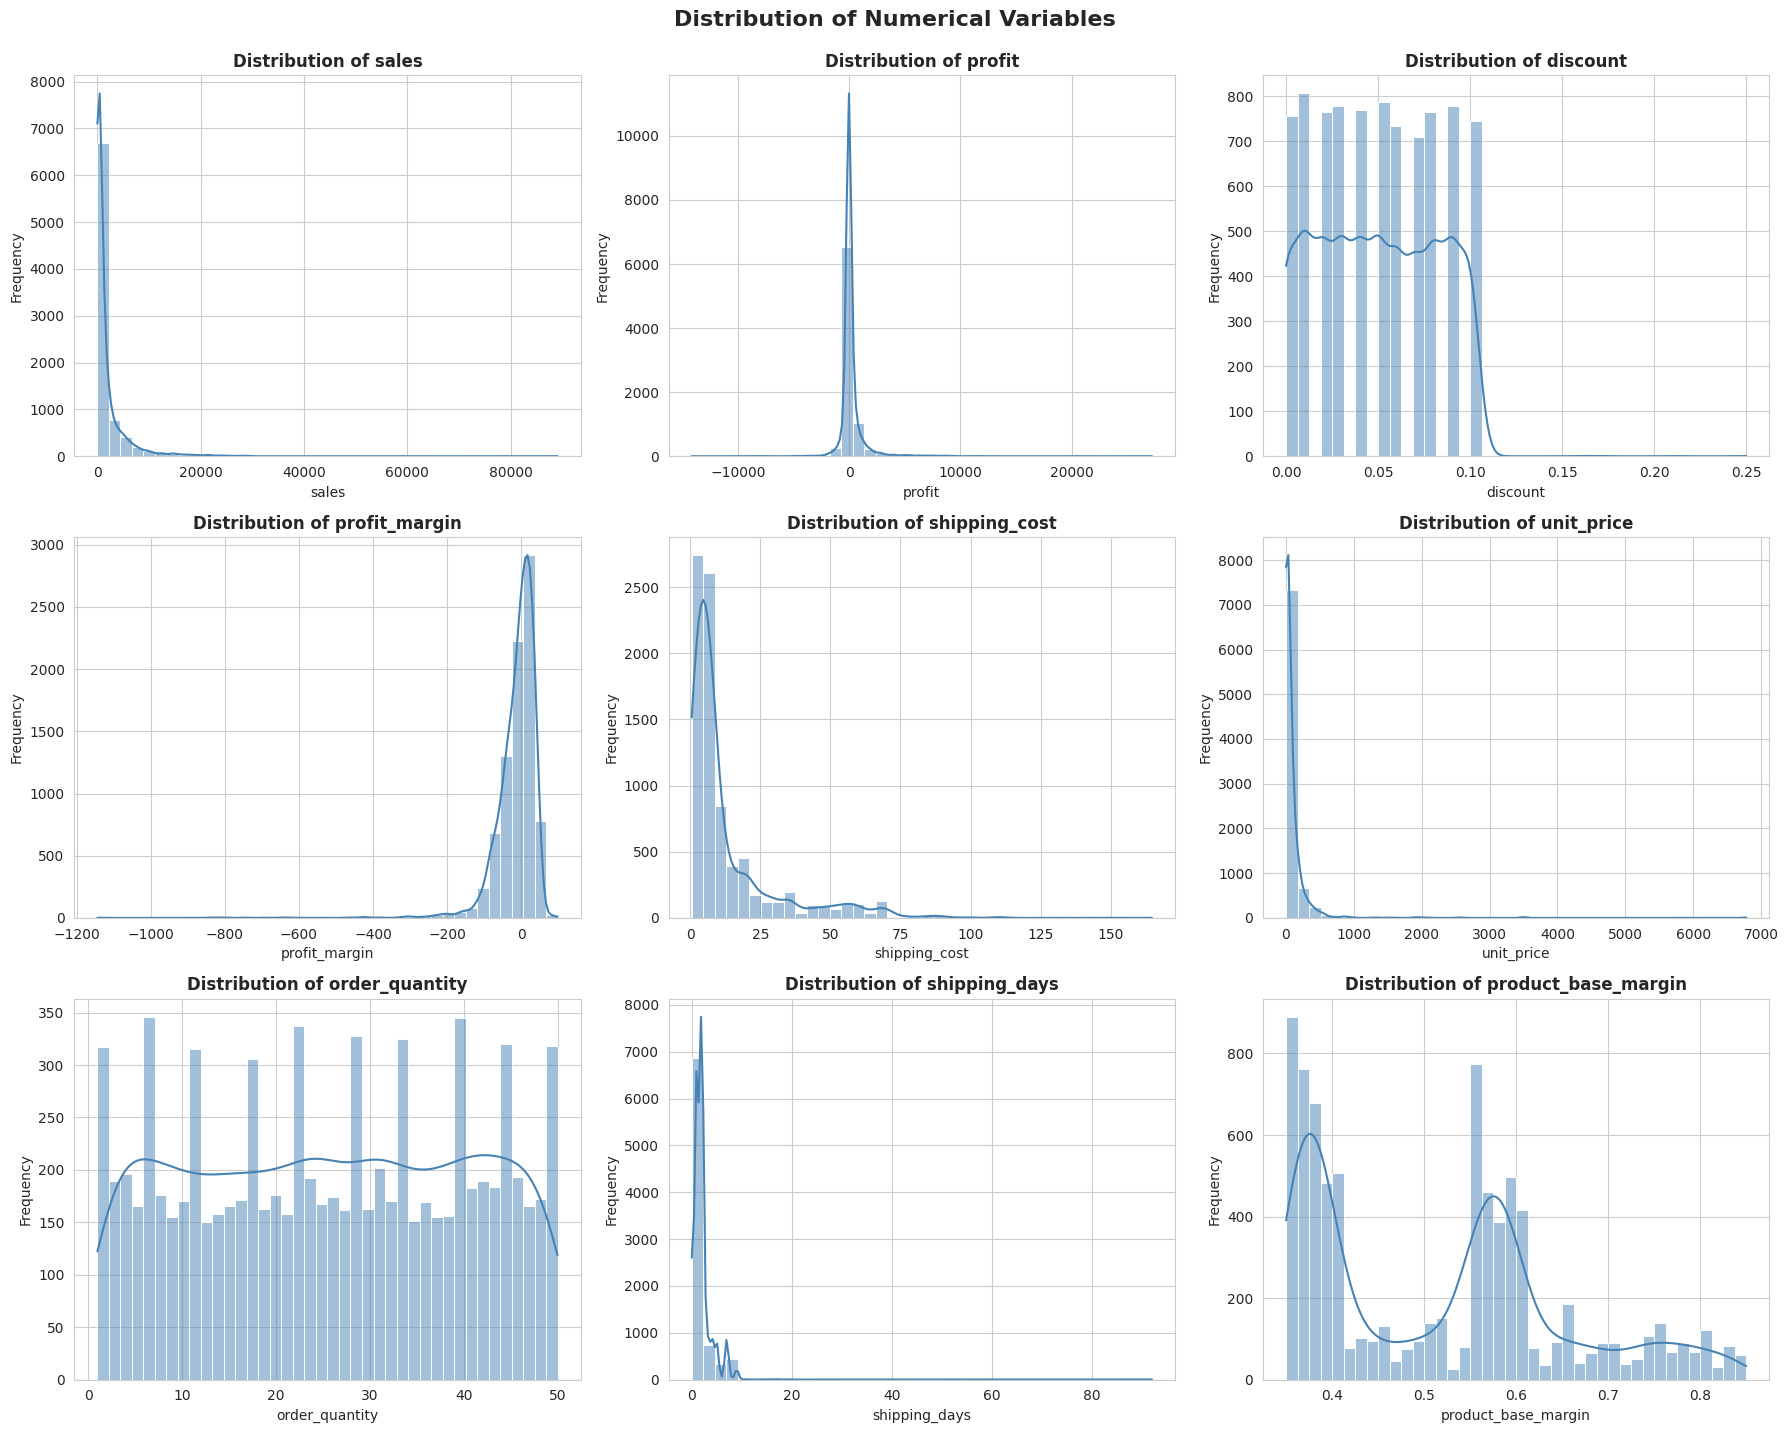

In [ ]:
fig, axes = plt.subplots(3, 3, figsize = (18, 14))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
  sns.histplot(df[col], kde = True, ax = axes[i], color = "steelblue", bins = 40)
  axes[i].set_title(f"Distribution of {col}", fontsize=12, fontweight="bold")
  axes[i].set_xlabel(col)
  axes[i].set_ylabel("Frequency")

plt.tight_layout()
plt.suptitle("Distribution of Numerical Variables", fontsize=16, fontweight="bold", y=1.02)
plt.show()

** Key Observations**

- Most variables (`sales`, `profit`, `unit_price`, `shipping_cost`) are **heavily
  right-skewed** — a small number of large orders stretch each distribution far
  beyond the typical range.
- `profit_margin` is **left-skewed**, dragged down by extreme loss-making orders
  (as low as -1,144%).
- `shipping_days` is the most extreme case — 75%+ of orders ship within 2 days,
  yet a handful stretch to 92 days.
- `product_base_margin` is unexpectedly **bimodal** (two peaks) — worth investigating
  further, possibly tied to product category or pricing strategy.

Averages alone would be misleading here — extreme values are clearly present across
most variables.

### 3.3 Outlier Detection — IQR Method

We now formally identify outliers rather than relying on visual impression alone.
We use the **Interquartile Range (IQR) method**, the standard statistical approach
for outlier detection, to quantify exactly how many outliers exist in each numerical
column and isolate them for closer inspection — including the known shipping_days
and profit_margin extremes flagged during cleaning.

In [ ]:
def detect_outliers_iqr(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = data[(data[column] < lower_bound) | (data[column] > upper_bound)]
    return outliers, lower_bound, upper_bound

outlier_summary = []

for col in numerical_cols:
    outliers, lower, upper = detect_outliers_iqr(df, col)
    outlier_summary.append({
        "column": col,
        "lower_bound": round(lower, 2),
        "upper_bound": round(upper, 2),
        "outlier_count": len(outliers),
        "outlier_percentage": round((len(outliers) / len(df)) * 100, 2)
    })

outlier_summary_df = pd.DataFrame(outlier_summary)
print(outlier_summary_df.to_string(index=False))

             column  lower_bound  upper_bound  outlier_count  outlier_percentage
              sales     -2205.99      4058.51           1042               12.41
             profit      -452.41       531.84           1704               20.29
           discount        -0.07         0.17              3                0.04
      profit_margin      -116.34       104.33            247                2.94
      shipping_cost       -12.74        30.03            972               11.57
         unit_price      -112.78       205.26            848               10.10
     order_quantity       -24.50        75.50              0                0.00
      shipping_days        -0.50         3.50           1143               13.61
product_base_margin         0.07         0.90              0                0.00


**Key Observations**

- `profit` has the highest outlier rate (**20.29%**) — roughly 1 in 5 orders.
  `shipping_days`, `sales`, `shipping_cost`, and `unit_price` also show high
  outlier rates (10–14%).
- `discount`, `order_quantity`, and `product_base_margin` show negligible outliers.

**Caveat:** IQR flags statistical rarity, not errors — e.g. any shipment over 3.5
days gets flagged, even though 4–5 days is perfectly normal. Each case needs human
judgment, not automatic removal.

### 3.4 Visualizing Outliers — Box Plots

Box plots show outliers directly as individual points beyond the IQR "fence," letting
us see not just how many outliers exist, but how extreme they are. This helps us
distinguish mildly unusual values from genuinely extreme cases worth investigating
individually — like the 92-day shipping order and the -1144% profit margin order
flagged during cleaning.

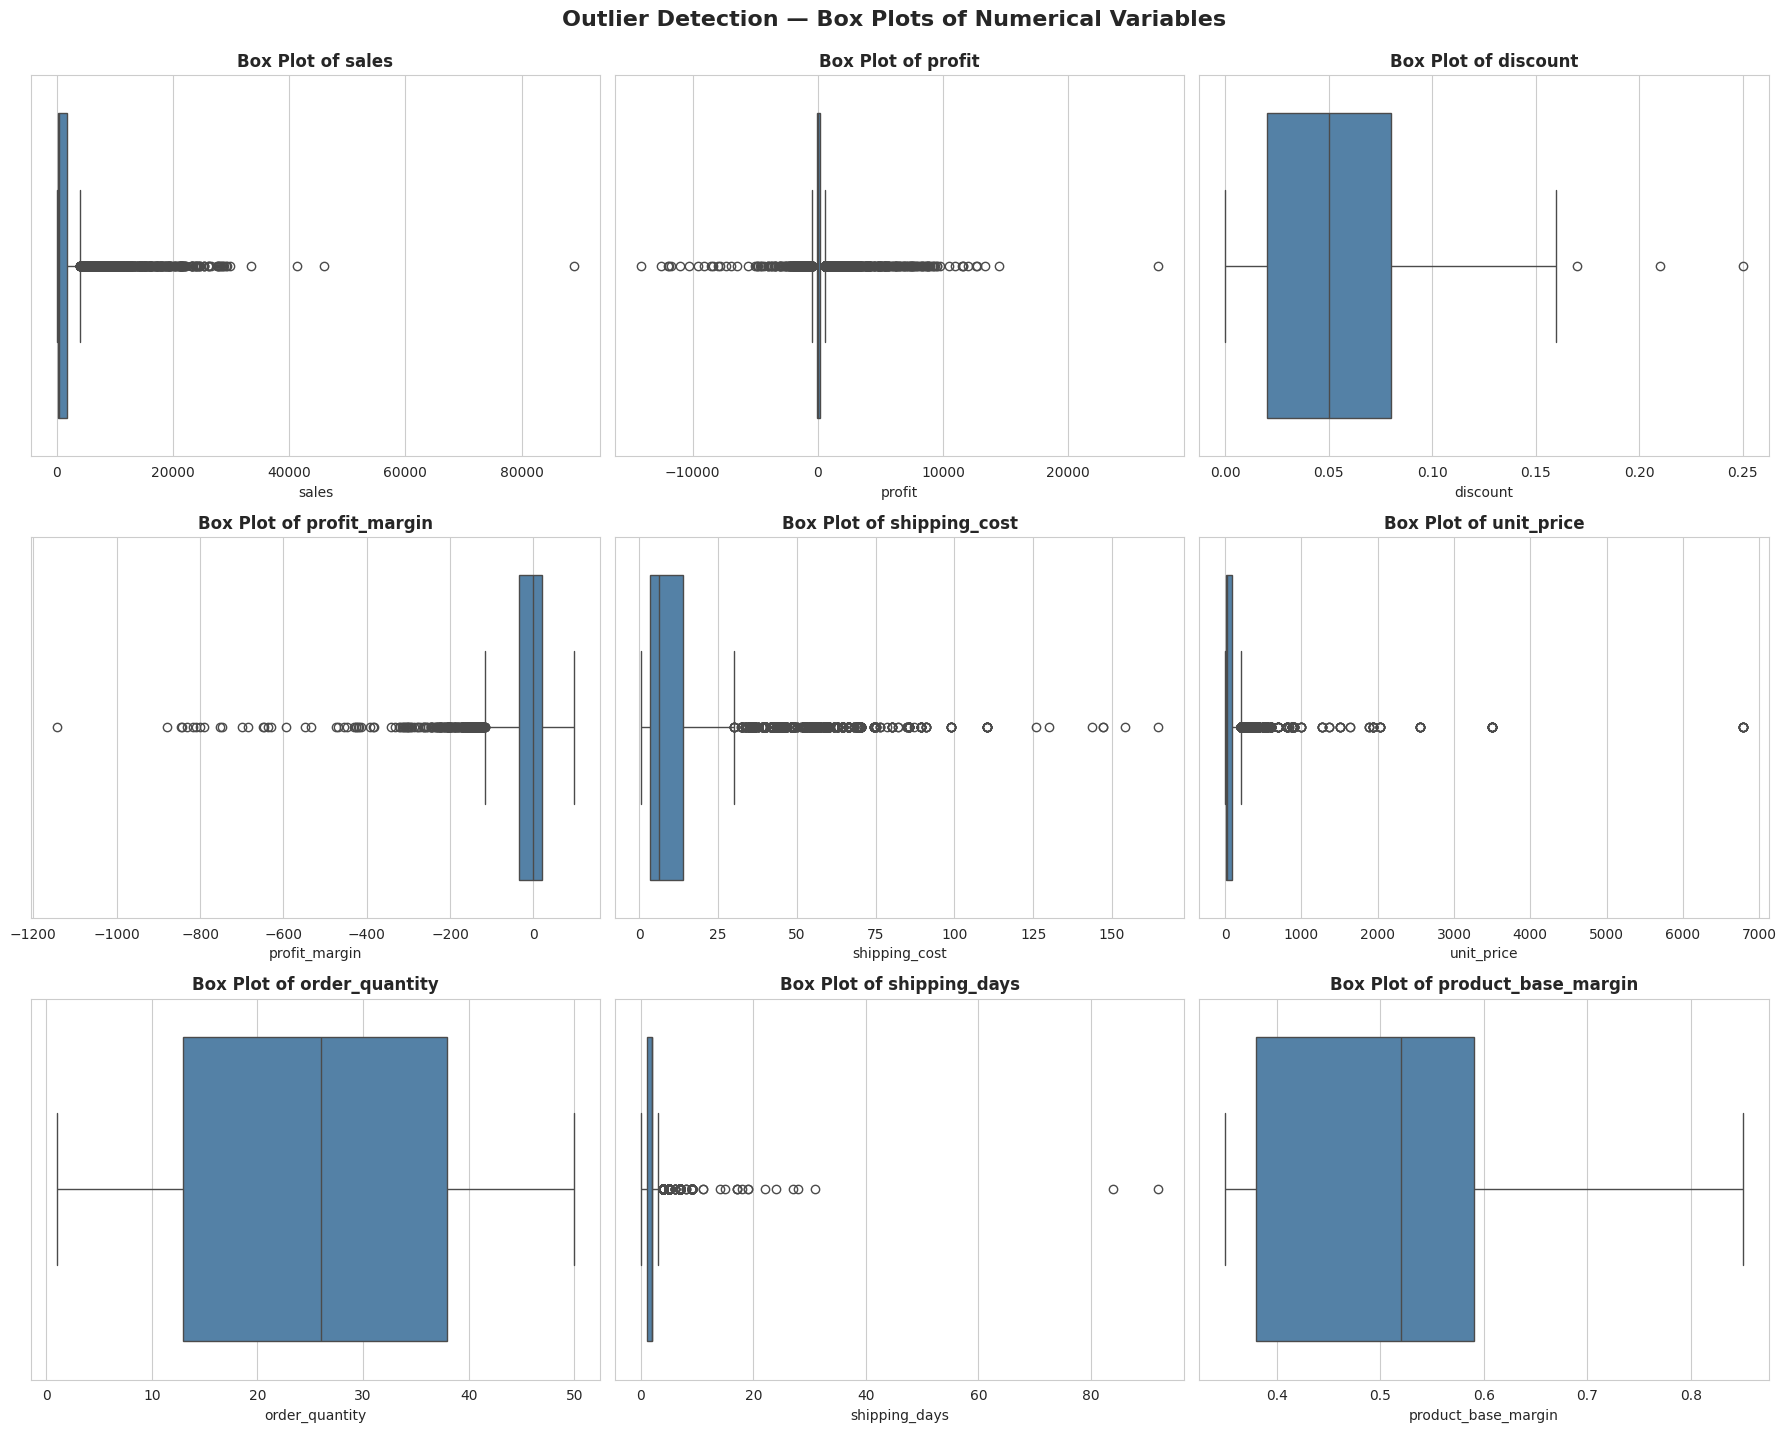

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    sns.boxplot(x=df[col], ax=axes[i], color="steelblue")
    axes[i].set_title(f"Box Plot of {col}", fontsize=12, fontweight="bold")
    axes[i].set_xlabel(col)

plt.tight_layout()
plt.suptitle("Outlier Detection — Box Plots of Numerical Variables",
             fontsize=16, fontweight="bold", y=1.02)
plt.show()

**Key Observations**

Box plots confirm not just *how many* outliers exist, but *how extreme* they are:
- A single `sales` outlier near **\$90,000** and a `profit` outlier near **\$27,000**
  stand far apart from the rest.
- `profit_margin` outliers stretch continuously to **-1,200%**.
- `shipping_days` shows isolated extreme cases near **85–92 days**, far from the
  tightly clustered 0–2 day norm.

These extreme cases are investigated individually in the next section.

### 3.5 Investigating Extreme Outliers

Statistics and charts tell us *that* extreme outliers exist — this section identifies
**exactly which orders** they are, so we can understand the real-world context behind
them rather than treating them as abstract numbers.

We examine two specific cases flagged throughout this analysis:
- The order with the **longest shipping time** (~92 days)
- The order with the **most extreme negative profit margin** (~-1,144%)

In [ ]:
context_cols = ["order_id", "order_date", "ship_date", "shipping_days",
                 "customer_name", "region", "product_category",
                 "product_sub_category", "sales", "profit", "profit_margin",
                 "discount", "order_priority"]

longest_shipping = df.loc[df["shipping_days"].idxmax()]
print("Longest Shipping Time Order:")
print(longest_shipping[context_cols])

print("\n" + "="*60 + "\n")

worst_margin = df.loc[df["profit_margin"].idxmin()]
print("Most Extreme Negative Profit Margin Order:")
print(worst_margin[context_cols])

Longest Shipping Time Order:
order_id                                353
order_date              2010-12-30 00:00:00
ship_date               2011-04-01 00:00:00
shipping_days                            92
customer_name                   Dean Percer
region                                 West
product_category            Office Supplies
product_sub_category    Pens & Art Supplies
sales                                 46.94
profit                                 3.88
profit_margin                          8.27
discount                               0.02
order_priority                          Low
Name: 59, dtype: object


Most Extreme Negative Profit Margin Order:
order_id                              13088
order_date              2010-04-22 00:00:00
ship_date               2010-04-24 00:00:00
shipping_days                             2
customer_name                    Ben Ferrer
region                                 East
product_category            Office Supplies
product_sub_category  

**Key Observations — Extreme Outlier Cases**

**Order #353 — 92-Day Shipping Delay**
- Shipped **91 days late** relative to typical delivery (Dec 30, 2010 → Apr 1, 2011)
- Despite the extreme delay, the order itself was **small and unremarkable** —
  46.94 dollars in sales, a modest 3.88 dollars profit, and only 2% discount
- `order_priority` is marked **Low** — this may partly explain the delay, though 92
  days is still extreme even for low-priority shipping
- **Conclusion:** This appears to be an **isolated operational/logistics anomaly**,
  not a pattern tied to product, discount, or profitability

**Order #13088 — Most Extreme Loss (-1,144% Margin)**
- A small sale of **187.92 dollars** resulted in a loss of **-$2,149.80** — the cost of
  fulfilling this order was over **11× the sale price itself**
- Shipped normally (2 days) — this was **not** a shipping or logistics issue
- Discount was only 8%, ruling out excessive discounting as the cause
- Category: **Office Supplies → Appliances** — notably, Office Supplies was already
  identified in Notebook 2 as the most loss-affected category
- **Conclusion:** This points toward a **structural cost or pricing issue** (e.g.
  shipping cost or base cost far exceeding sale price for this specific product),
  not a discounting or delivery problem

**Business Insight:** These two extreme cases have **completely different root
causes** — one is a logistics/shipping-time anomaly, the other is a pricing/cost
structure problem. This reinforces the earlier finding that discount level alone
does not explain the dataset's profitability issues; multiple distinct factors are
at play across different orders.

In [ ]:
print(df.loc[1819, ["sales", "shipping_cost", "profit", "unit_price", "order_quantity", "discount"]])

sales              187.92
shipping_cost       49.00
profit           -2149.80
unit_price           3.25
order_quantity         46
discount             0.08
Name: 1819, dtype: object


**Root Cause — Order #13088 Extreme Loss**

- Shipping cost (**\$49.00**) is far too small to explain a loss of **-\$2,149.80** —
  ruling out shipping as the cause
- The remaining ~**\$2,289** in unexplained cost strongly suggests the **product
  itself was sold below its true cost** — at \$3.25/unit × 46 units, this looks like
  a **severe underpricing issue**, not an operational or shipping problem
- The calculated `sales` figure (\$187.92) does not perfectly reconcile with
  `unit_price × quantity × discount` (\$137.54 expected) — a minor data inconsistency
  worth noting, though not the primary driver of the loss

**Business Insight:** Unlike Order #353 (a logistics anomaly), this case points to
a **pricing/costing problem** — the business may be underpricing certain
Office Supplies → Appliances products relative to their true cost, especially at
higher order quantities. This is a distinct root cause from both shipping delays and
discounting, reinforcing that Superstore's profitability issues stem from multiple,
separate underlying problems.

## 4️ Univariate Analysis — Categorical Variables

We now examine each categorical variable individually — frequency counts and
proportions — to understand how orders are distributed across regions, customer
segments, product categories, shipping modes, order priorities, and discount/sales
bands.

In [ ]:
categorical_cols = ["region", "customer_segment", "product_category",
                     "ship_mode", "order_priority", "discount_band", "sales_band"]

for col in categorical_cols:
    print(f"\n{'='*50}")
    print(f"Value Counts — {col}")
    print(f"{'='*50}")
    counts = df[col].value_counts()
    percentages = df[col].value_counts(normalize=True) * 100
    summary = pd.DataFrame({"count": counts, "percentage": percentages.round(2)})
    print(summary.to_string())


Value Counts — region
         count  percentage
region                    
Central   2710       32.27
West      1956       23.29
East      1895       22.56
South     1838       21.88

Value Counts — customer_segment
                  count  percentage
customer_segment                   
Corporate          3076       36.62
Home Office        2032       24.19
Consumer           1649       19.63
Small Business     1642       19.55

Value Counts — product_category
                  count  percentage
product_category                   
Office Supplies    4610       54.89
Technology         2065       24.59
Furniture          1724       20.53

Value Counts — ship_mode
                count  percentage
ship_mode                        
Regular Air      6270       74.65
Delivery Truck   1146       13.64
Express Air       983       11.70

Value Counts — order_priority
                count  percentage
order_priority                   
High             1768       21.05
Low              1720   

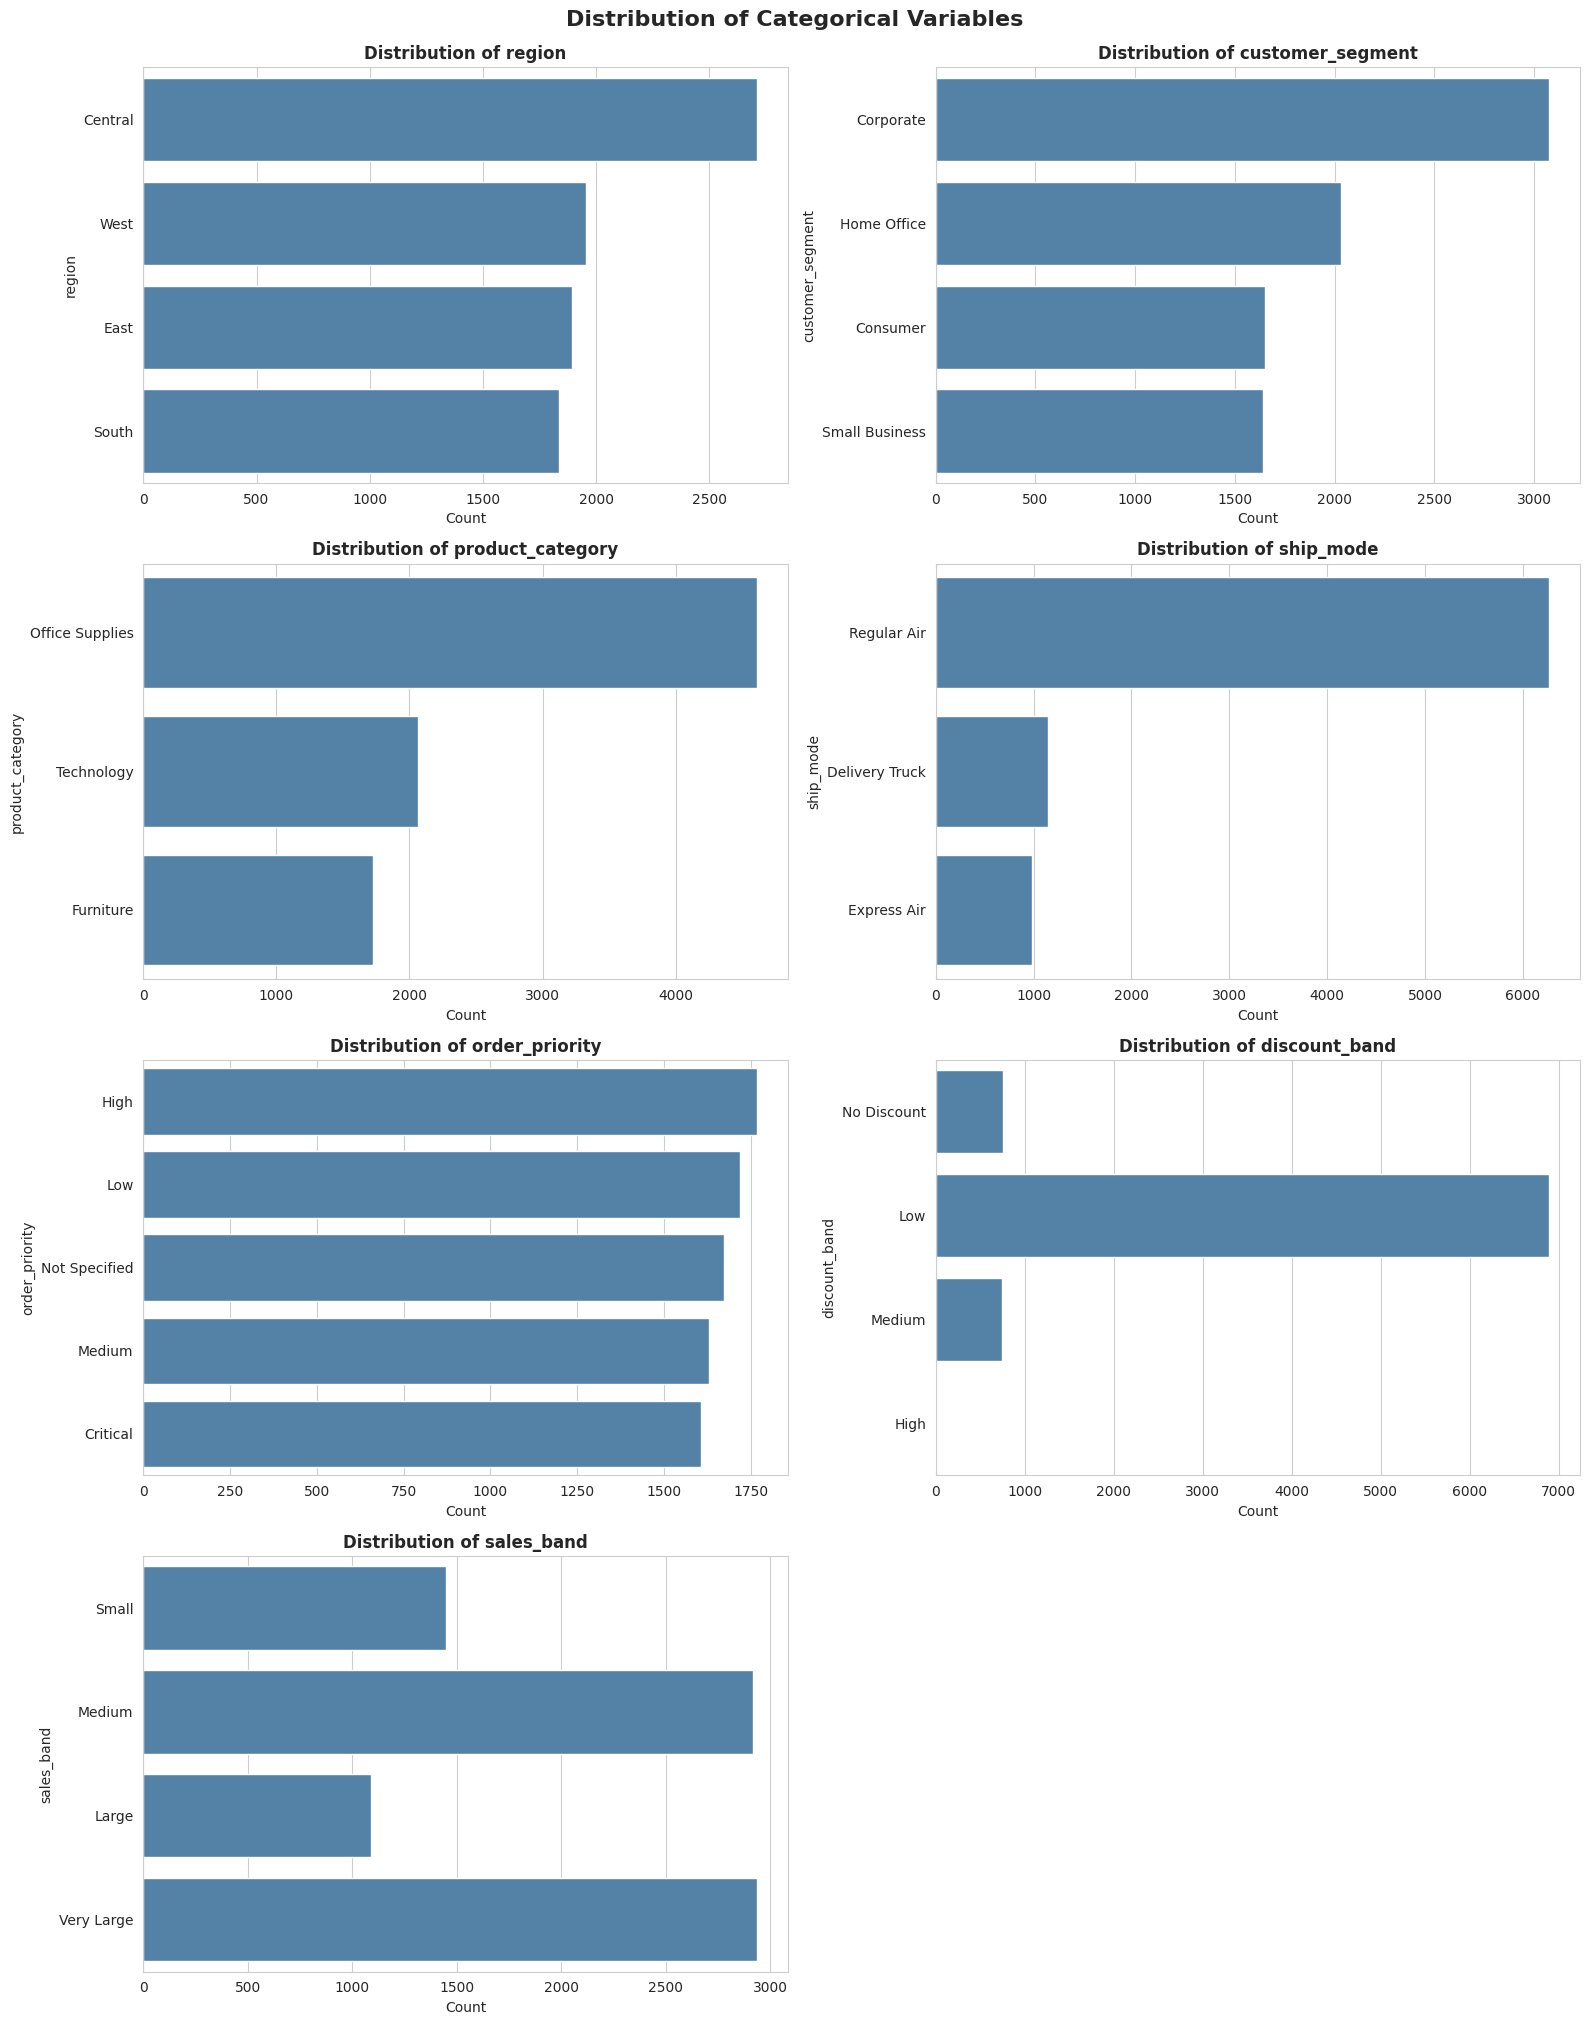

In [ ]:
fig, axes = plt.subplots(4, 2, figsize=(16, 20))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    order = df[col].value_counts().index if col not in ["discount_band", "sales_band"] else None
    sns.countplot(data=df, y=col, ax=axes[i], color="steelblue", order=order)
    axes[i].set_title(f"Distribution of {col}", fontsize=12, fontweight="bold")
    axes[i].set_xlabel("Count")

fig.delaxes(axes[7])
plt.tight_layout()
plt.suptitle("Distribution of Categorical Variables", fontsize=16, fontweight="bold", y=1.01)
plt.show()

**Key Observations — Categorical Distributions**

- **Region:** Central leads (~2,700+ orders), followed by West, East, and South fairly
  evenly — no single region dominates overwhelmingly.
- **Customer Segment:** **Corporate** is the largest segment (**36.62%**), notably
  ahead of Home Office (24.19%), Consumer (19.63%), and Small Business (19.55%) —
  the business skews toward corporate buyers.
- **Product Category:** **Office Supplies dominates** at **54.89%** — more than
  double Technology (24.59%) and Furniture (20.53%) combined relative share. This is
  significant given Office Supplies was already flagged as the most loss-affected
  category — high volume in a loss-prone category compounds the profitability issue.
- **Ship Mode:** **Regular Air is overwhelmingly dominant** (**74.65%**) — Delivery
  Truck and Express Air are minor by comparison (13.64% and 11.70%).
- **Order Priority:** Remarkably even split across all five levels (~19–21% each) —
  no meaningful skew, suggesting priority is assigned fairly uniformly rather than
  concentrated at any one urgency level.
- **Discount Band:** **82.07% of orders fall in the "Low" discount band** — deep
  discounting is rare, with "High" being almost nonexistent (2 orders, 0.02%). This
  reinforces the earlier finding that discounting is not a widespread driver of
  losses — it simply isn't happening at scale.
- **Sales Band:** Fairly bimodal — **Very Large (34.97%) and Medium (34.77%)**
  orders dominate almost equally, while **Large** orders are the least common
  (13.00%), an unusual dip worth noting.

**Business Insight:** The heavy concentration in **Office Supplies** — the
category already identified as most loss-prone — combined with minimal discounting
overall, strengthens the earlier conclusion that **losses are structural (pricing/cost
related), not discount-driven**. The business's overreliance on a single low-margin
category is a strategic concern worth surfacing in Notebook 4.

## 5️ Bivariate Analysis — Correlation Between Numerical Variables

We examine relationships between numerical variables using a correlation matrix and
heatmap. This helps identify which variables move together — for example, whether
`discount` truly has little relationship with `profit`, as suspected since Notebook 2.

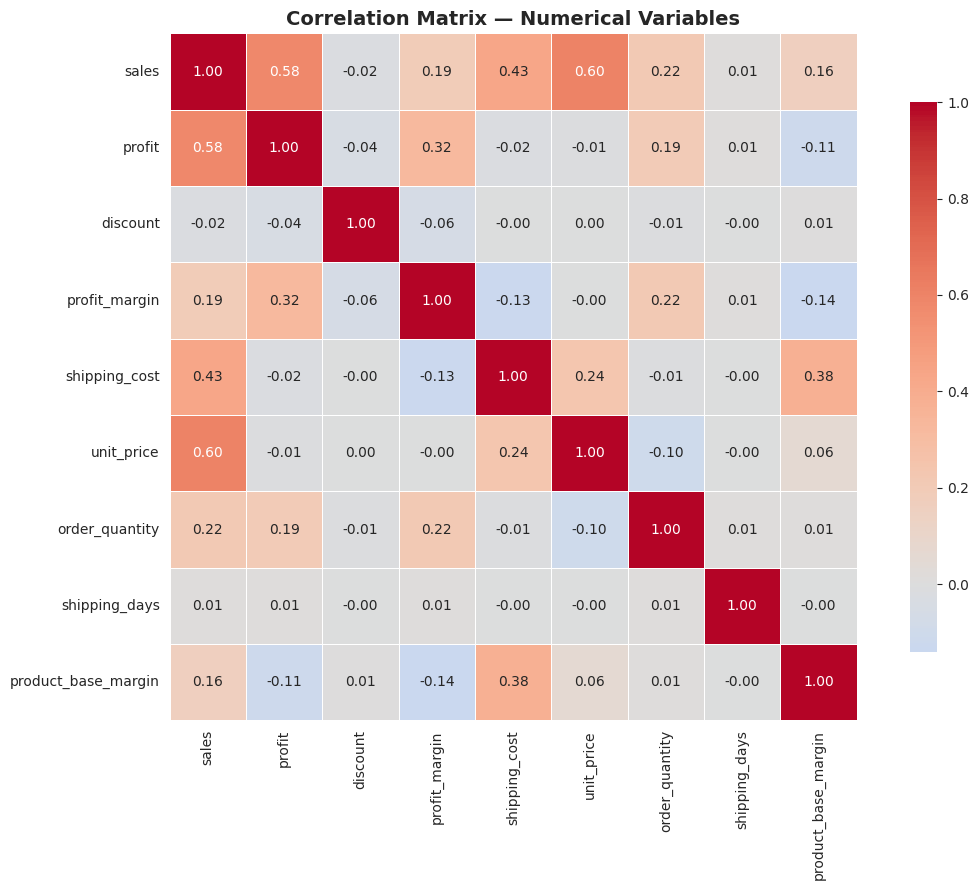

In [ ]:
corr_cols = ["sales", "profit", "discount", "profit_margin", "shipping_cost",
             "unit_price", "order_quantity", "shipping_days", "product_base_margin"]

corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Correlation Matrix — Numerical Variables", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

**Key Observations — Correlation Analysis**

- **`discount` vs `profit`: -0.04** — essentially **no meaningful correlation**.
  This statistically confirms what Notebook 2 suspected: discounting is **not** a
  driver of losses in this dataset.
- **`discount` vs `profit_margin`: -0.06** — also negligible. Discount level has
  almost no linear relationship with profitability at all, reinforcing that the
  root cause of losses lies elsewhere (as we found directly with Order #13088).
- **`sales` vs `profit`: 0.58** — a moderate positive relationship, as expected:
  higher-value orders tend to generate more profit, though the relationship isn't
  extremely strong, meaning **high sales don't guarantee high profit**.
- **`sales` vs `unit_price`: 0.60`** — the strongest relationship in the matrix;
  makes intuitive sense, since expensive items naturally drive up total sale value.
- **`shipping_cost` vs `product_base_margin`: 0.38`** — a moderate positive link,
  suggesting products with higher shipping costs also tend to carry higher margins
  (possibly bulkier/premium items priced accordingly).
- **`profit_margin` vs `shipping_cost`: -0.13** and **`profit_margin` vs
  `product_base_margin`: -0.14`** — both weak negative relationships, mild signals
  worth noting but not strong enough to be primary drivers on their own.
- **`shipping_days`** shows **near-zero correlation with everything** (all values
  ≈ 0.00–0.01) — shipping time does not meaningfully relate to sales, profit, or any
  other numerical variable. This reinforces that the 92-day outlier (Order #353) was
  a true isolated anomaly, not part of a broader pattern.

**Business Insight:** The most important finding here is the **near-zero
correlation between `discount` and both `profit` and `profit_margin`** — this is
strong statistical proof that discounting is not the business's profitability
problem. Combined with the earlier root-cause finding on Order #13088, the evidence
consistently points toward **pricing/cost structure issues**, not discount strategy,
as the primary driver of losses.

## 6️ Bivariate Analysis — Numeric vs Categorical

We compare key numerical variables (`profit_margin`, `sales`) across categorical
groupings (`region`, `product_category`, `customer_segment`) using box plots. This
reveals whether certain groups are systematically more profitable — or more
loss-prone — than others.

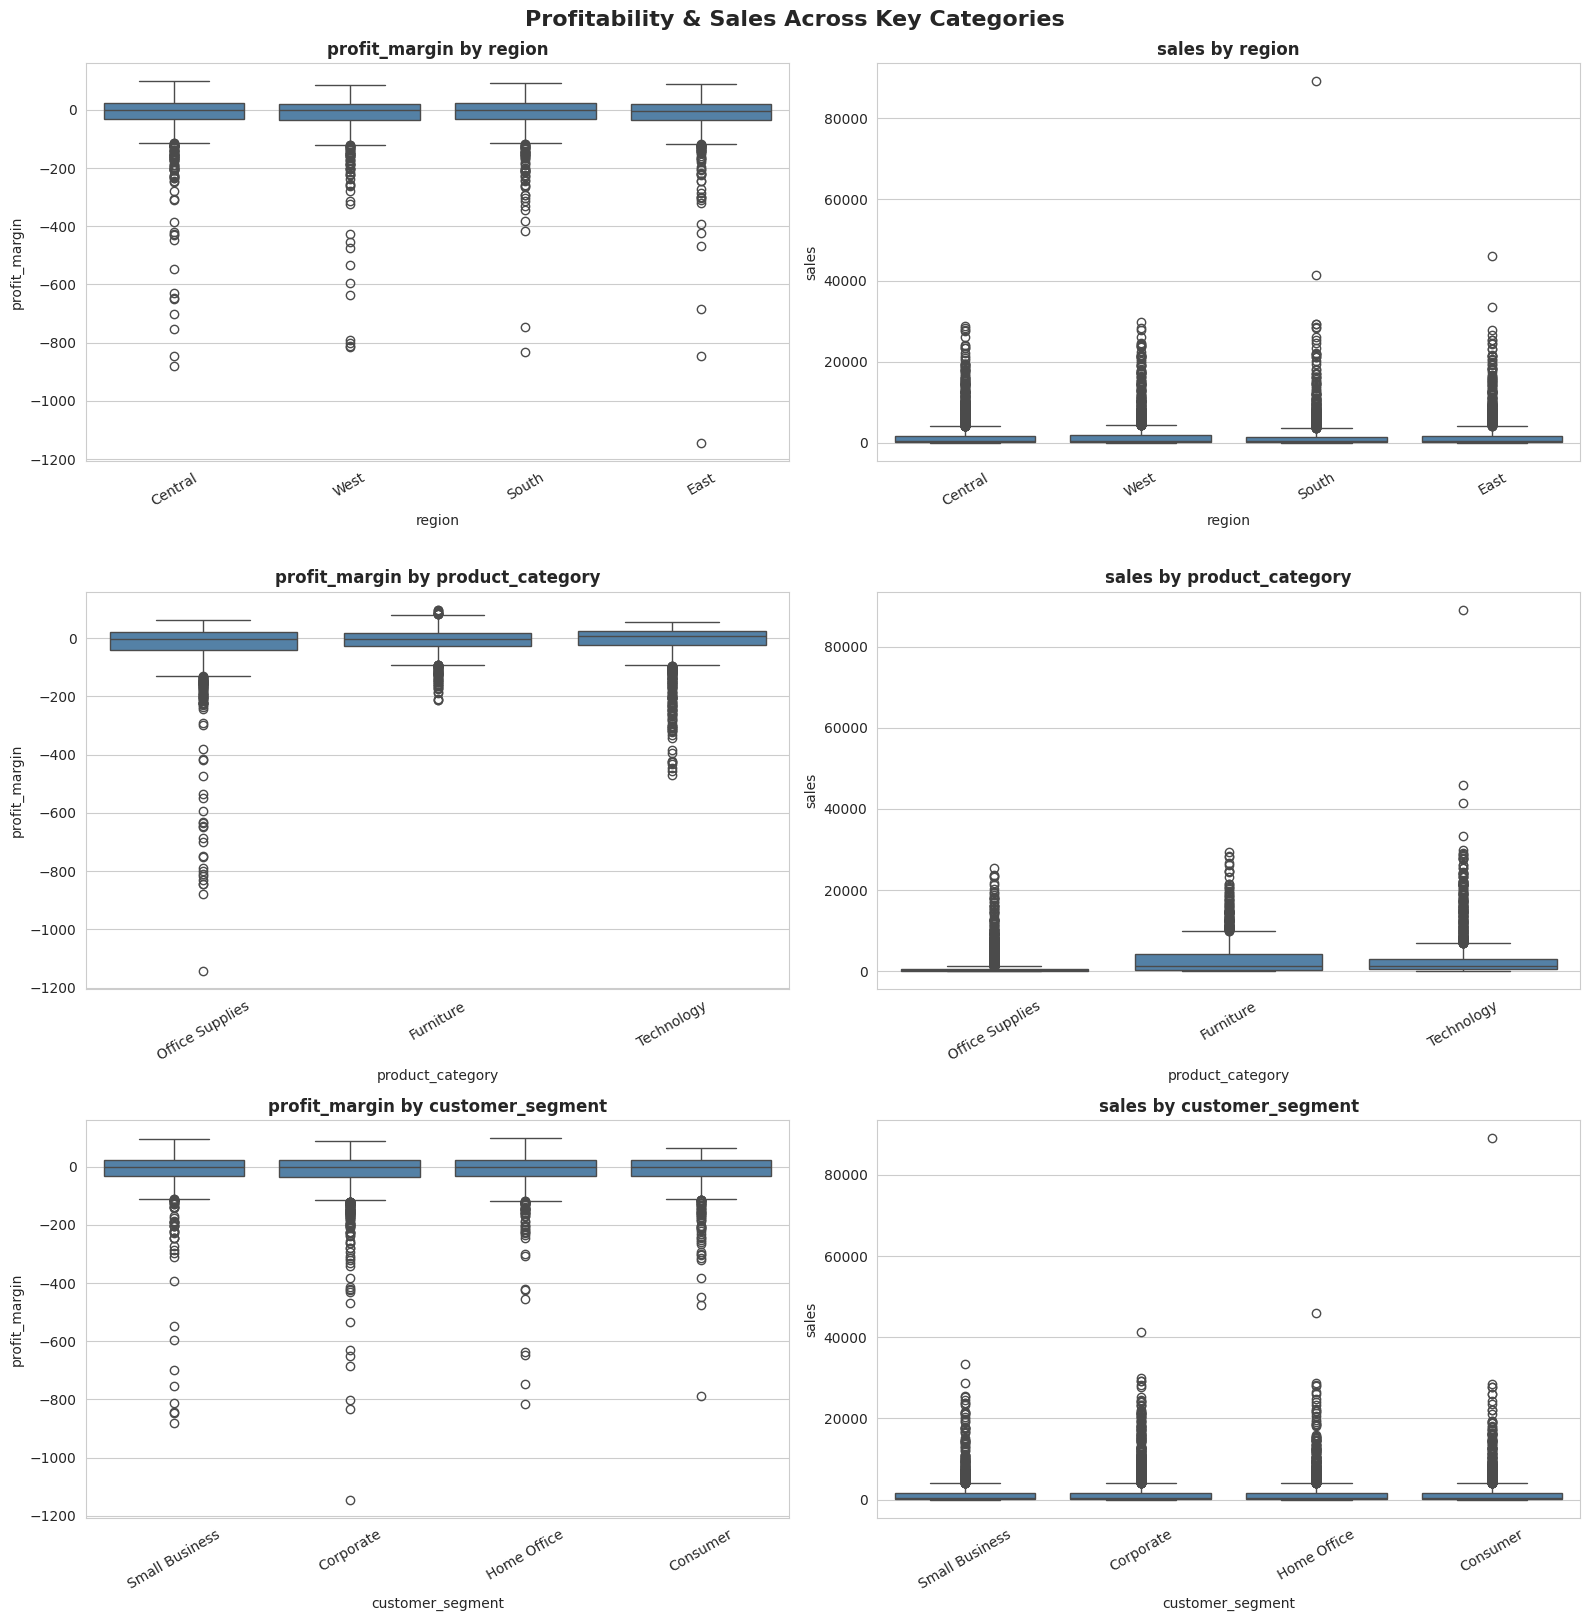

In [ ]:
fig, axes = plt.subplots(3, 2, figsize=(16, 16))

pairs = [
    ("region", "profit_margin"), ("region", "sales"),
    ("product_category", "profit_margin"), ("product_category", "sales"),
    ("customer_segment", "profit_margin"), ("customer_segment", "sales")
]

for i, (cat_col, num_col) in enumerate(pairs):
    row, col_pos = divmod(i, 2)
    sns.boxplot(data=df, x=cat_col, y=num_col, ax=axes[row, col_pos], color="steelblue")
    axes[row, col_pos].set_title(f"{num_col} by {cat_col}", fontsize=12, fontweight="bold")
    axes[row, col_pos].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.suptitle("Profitability & Sales Across Key Categories", fontsize=16, fontweight="bold", y=1.01)
plt.show()

**Key Observations — Numeric vs Categorical Patterns**

**Profit Margin by Region**
- All four regions show **strikingly similar patterns** — medians near 0, similar
  spread, and comparable extreme negative outliers (down to roughly -800 to -1150).
  **No single region stands out as uniquely problematic** — losses appear to be a
  business-wide issue, not a regional one.

**Profit Margin by Product Category — Most important panel**
- **Office Supplies** shows the **widest spread of negative outliers**, with losses
  extending all the way to **-1150%** (this is Order #13088) and a dense cluster of
  moderate losses between -200 and -800.
- **Furniture** has the **tightest, cleanest distribution** — very few extreme
  negative outliers, suggesting it's the most stable category profitability-wise.
- **Technology** shows a **notable cluster of losses down to -400/-450**, more
  contained than Office Supplies but still a meaningful loss pattern.
- **This visually confirms Notebook 2's finding**: Office Supplies is the most
  loss-affected category, and now we can see it's not just *volume* of losses —
  it's also the *severity* of individual extreme losses.

**Profit Margin by Customer Segment**
- Again, **fairly uniform across all four segments** — no segment is dramatically
  more loss-prone than another, though Corporate shows the single most extreme
  outlier (~-1150%, matching Order #13088, which is a Corporate transaction).

**Sales Distributions (right column)**
- All three groupings (region, category, segment) show the same heavily right-skewed
  pattern seen earlier — dominated by the single ~\$89,000 outlier sale, which
  appears to belong to the Technology category based on its position in that panel.
- **Furniture** shows a **visibly higher median sales box** than Office Supplies,
  despite Office Supplies having far more orders — consistent with Furniture being
  lower-volume but higher-value per transaction.

**Business Insight:** The profitability problem is **not regional and not
segment-specific** — it is heavily concentrated in the **Office Supplies category**,
both in frequency and severity of losses. This strengthens the case that Notebook 4
should prioritize category-level pricing/cost investigation over regional or
segment-based strategies.

## 7️ Profitability Pattern Exploration

Profitability is the central theme of this dataset — over 50% of orders are
unprofitable. This section examines how the profitable vs. unprofitable split
behaves across product category, region, and discount band, consolidating evidence
for the deeper business analysis in Notebook 4.

In [ ]:
profitable_counts = df["is_profitable"].value_counts()
profitable_pct = df["is_profitable"].value_counts(normalize=True) * 100

print("Overall Profitability Split:")
print(pd.DataFrame({"count": profitable_counts, "percentage": profitable_pct.round(2)}))

Overall Profitability Split:
               count  percentage
is_profitable                   
False           4264       50.77
True            4135       49.23


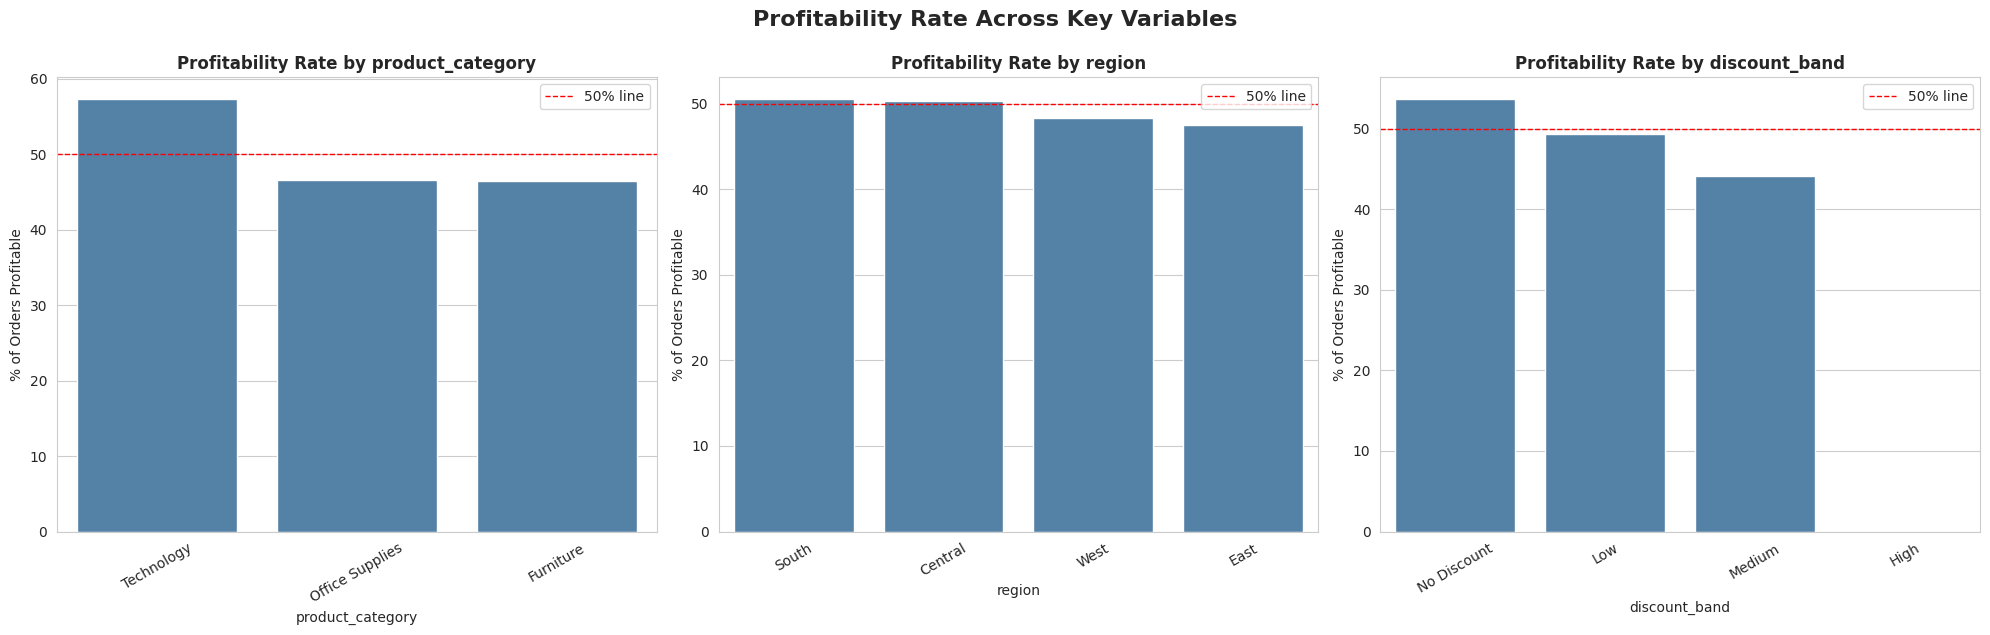

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

group_cols = ["product_category", "region", "discount_band"]

for i, col in enumerate(group_cols):
    profit_rate = df.groupby(col, observed=True)["is_profitable"].mean() * 100
    profit_rate = profit_rate.sort_values(ascending=False)
    sns.barplot(x=profit_rate.index, y=profit_rate.values, ax=axes[i], color="steelblue")
    axes[i].set_title(f"Profitability Rate by {col}", fontsize=12, fontweight="bold")
    axes[i].set_ylabel("% of Orders Profitable")
    axes[i].axhline(50, color="red", linestyle="--", linewidth=1, label="50% line")
    axes[i].tick_params(axis='x', rotation=30)
    axes[i].legend()

plt.tight_layout()
plt.suptitle("Profitability Rate Across Key Variables", fontsize=16, fontweight="bold", y=1.05)
plt.show()

**Key Observations — Profitability Rate Analysis**

**Overall Split**
- **50.77% of orders are unprofitable** (4,264) vs **49.23% profitable** (4,135) —
  confirmed consistent with Notebook 2's original finding, no discrepancy after
  reload.

**By Product Category**
- **Technology is the only category above the 50% line** (~57% of orders profitable)
  — the healthiest category in the dataset.
- **Office Supplies (~46%) and Furniture (~46%)** both sit below the profitability
  tipping point, at nearly identical rates.
- **Important nuance:** while Office Supplies and Furniture have *similar
  profitability rates*, the earlier box plot analysis showed Office Supplies has
  **far more extreme and severe losses** (down to -1150%) and **much higher order
  volume**. This means Office Supplies is the bigger business problem — not because
  it fails more *often* per order, but because it fails at a much **larger scale**,
  compounding total financial impact.

**By Region**
- All four regions cluster **tightly around the 50% line** (South and Central
  slightly above, West and East slightly below) — confirming the earlier finding
  that profitability issues are **not regionally concentrated**. This is a
  business-wide pattern, not a location-specific one.

**By Discount Band**
- A mild **declining trend** is visible: No Discount (~54%) → Low (~49%) →
  Medium (~44%). Higher discount bands do show somewhat lower profitability rates.
- **However, this must be read carefully alongside the correlation analysis**, which
  found `discount` and `profit`/`profit_margin` have **near-zero linear correlation**
  (-0.04 and -0.06). The mild downward trend here is real but weak — discount is
  **not the primary driver** of the 50%+ loss rate; it may be a minor contributing
  factor at most, likely confounded by other variables (e.g., higher discounts might
  coincide with certain product types).

**Business Insight:** The profitability crisis is **broad-based and structural**
— not isolated to a specific region, and only partially related to discounting.
**Technology is the strongest-performing category**, while **Office Supplies
represents the highest-priority problem area** due to its combination of high
volume, below-average profitability rate, and the most severe individual loss cases
identified in this notebook. This sets a clear priority focus for the category-level
investigation planned in Notebook 4.

## 8️ Time-Based Structure Check

Before deeper time-series business analysis in Notebook 4, we verify the dataset's
time structure is sound — checking order distribution across years, quarters, and
days of the week, and confirming there are no unexpected gaps in coverage.

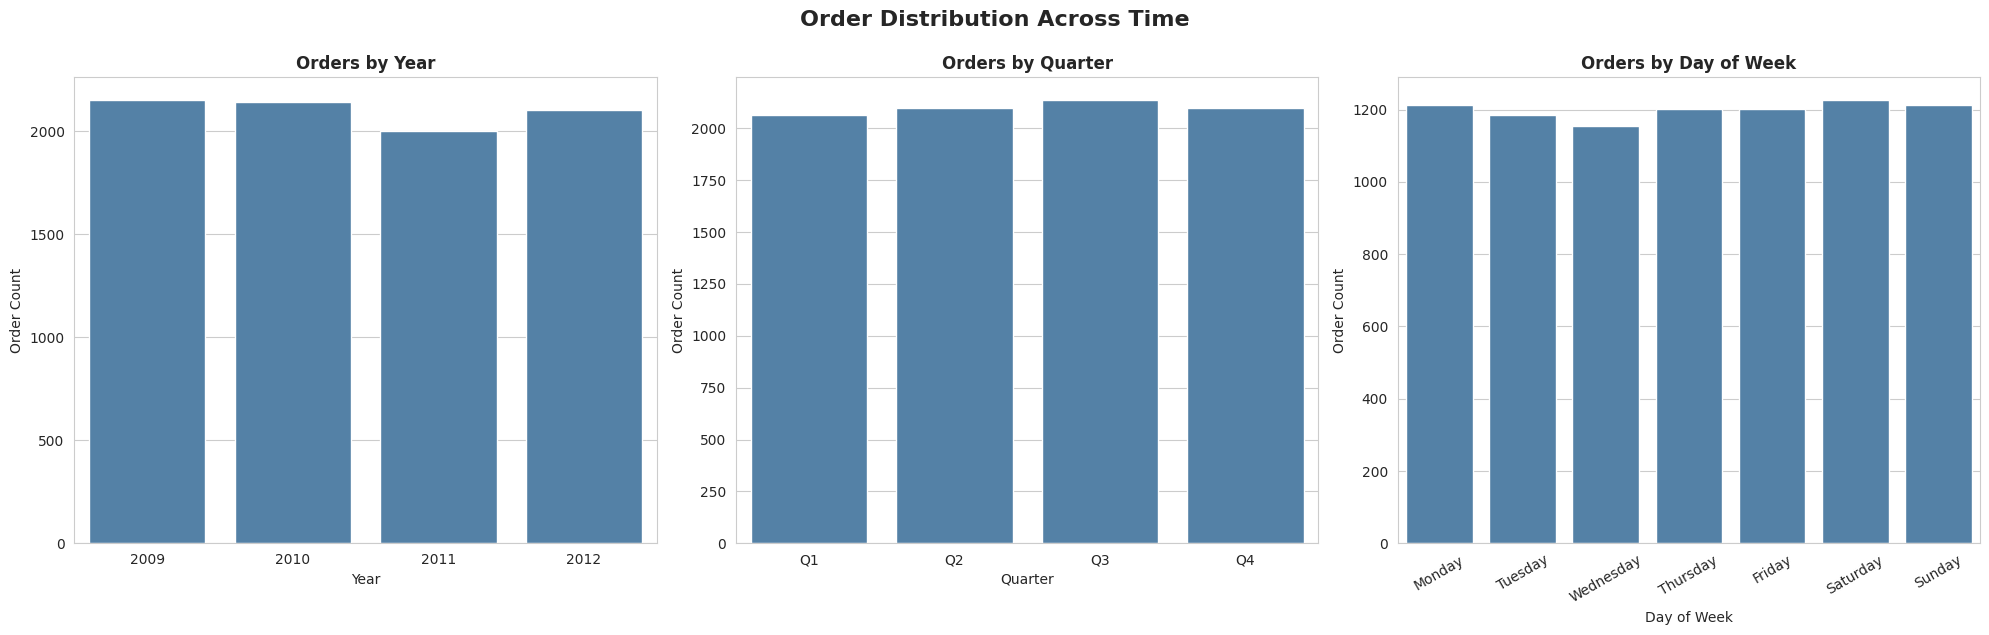

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

year_counts = df["year"].value_counts().sort_index()
sns.barplot(x=year_counts.index, y=year_counts.values, ax=axes[0], color="steelblue")
axes[0].set_title("Orders by Year", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Order Count")

quarter_counts = df["quarter"].value_counts().sort_index()
sns.barplot(x=quarter_counts.index, y=quarter_counts.values, ax=axes[1], color="steelblue")
axes[1].set_title("Orders by Quarter", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Quarter")
axes[1].set_ylabel("Order Count")

day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
day_counts = df["day_of_week"].value_counts().reindex(day_order)
sns.barplot(x=day_counts.index, y=day_counts.values, ax=axes[2], color="steelblue")
axes[2].set_title("Orders by Day of Week", fontsize=12, fontweight="bold")
axes[2].set_xlabel("Day of Week")
axes[2].set_ylabel("Order Count")
axes[2].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.suptitle("Order Distribution Across Time", fontsize=16, fontweight="bold", y=1.05)
plt.show()

In [ ]:
print(f"Date range: {df['order_date'].min()} to {df['order_date'].max()}")
print(f"Total days spanned: {(df['order_date'].max() - df['order_date'].min()).days}")
print(f"\nOrders per year:\n{df['year'].value_counts().sort_index()}")

Date range: 2009-01-01 00:00:00 to 2012-12-30 00:00:00
Total days spanned: 1459

Orders per year:
year
2009    2153
2010    2142
2011    2002
2012    2102
Name: count, dtype: int64


**Key Observations — Time Structure Check**

**Coverage**
- Data spans **2009-01-01 to 2012-12-30** — a full **1,459 days** (~4 years),
  matching expectations with no unexpected gaps in the date range.

**Orders by Year**
- Order volume is **fairly consistent across all four years** (~2,000–2,150 orders
  each), with **2011 showing a mild dip** (2,002 vs ~2,100–2,150 in other years).
  Not dramatic enough to flag as an anomaly, but worth noting as a minor observation
  — Notebook 4's year-over-year analysis can explore whether this dip relates to
  revenue or profit as well, not just order count.

**Orders by Quarter**
- Very evenly distributed (**Q1: ~2,050, Q2: ~2,070, Q3: ~2,090, Q4: ~2,060**) — no
  strong seasonal concentration in raw order count. Any seasonality in *revenue*
  (rather than order count) remains a question for Notebook 4.

**Orders by Day of Week**
- Reasonably even across all seven days, with **Wednesday showing the lowest count**
  (~1,160) and **Saturday the highest** (~1,250) — a mild pattern, not a dramatic one.
  Notably, **weekend order volume (Saturday, Sunday) is not meaningfully lower than
  weekdays**, which is slightly unusual for a B2B-leaning business (given Corporate
  is the largest customer segment) and could be worth a closer look in Notebook 4.

**Business Insight:** The dataset shows **no structural gaps or red flags** across
time — order volume is stable and well-distributed across years, quarters, and days
of week. This confirms the data is reliable for the time-series business questions
(seasonality, YoY growth, monthly trends) planned for Notebook 4.

##Summary & Key Findings — Exploratory Data Analysis

This notebook explored the structure, distributions, and relationships within the
cleaned Superstore dataset (8,399 rows × 33 columns, 2009–2012) across eight stages:
data quality verification, univariate analysis (numerical & categorical), outlier
detection, correlation analysis, bivariate exploration, profitability patterns, and
time structure validation.

###Key Findings

**1. Extreme Skewness Across Financial Variables**
`sales`, `profit`, `unit_price`, and `shipping_cost` are all heavily right-skewed,
while `profit_margin` is strongly left-skewed — confirming that averages alone are
misleading for this dataset without accounting for outliers.

**2. Two Extreme Outliers Investigated and Explained**
- **Order #353** — a 92-day shipping delay, traced to an isolated logistics
  anomaly unrelated to sales, profit, or product type.
- **Order #13088** — a -1,144% profit margin, traced to severe underpricing
  (\$3.25/unit × 46 units) rather than shipping cost or discounting.

**3. Discount Is Confirmed NOT a Driver of Losses**
Correlation between `discount` and both `profit` (-0.04) and `profit_margin` (-0.06)
is negligible — statistically confirming the finding first suspected in Notebook 2.

**4. Office Supplies Is the Priority Problem Area**
While its profitability *rate* (~46%) is similar to Furniture, Office Supplies
carries **far higher order volume** and **the most severe individual losses** in the
dataset — making it the category with the greatest total financial impact.

**5. Profitability Issues Are Business-Wide, Not Regional**
All four regions show nearly identical profitability rates (~47–50%), ruling out
any single region as the root cause.

**6. `product_base_margin` Is Bimodal**
Two distinct peaks (~0.38 and ~0.58) suggest possibly two different product pricing
or margin strategies — a lead worth exploring further in Notebook 4.

**7. No Structural Issues in Time Coverage**
Order volume is stable and evenly distributed across years, quarters, and days of
the week — the dataset is reliable for time-series analysis ahead.

###Next Steps
These findings — particularly the category-level loss concentration, the confirmed
lack of a discount-profit relationship, and the root causes behind the two extreme
outliers — set the foundation for **Notebook 4: Business Analysis**, where all 39
business questions will be answered using the patterns uncovered here.